# Predictions with Gaussian Process Regression (GPR)

<img src="img_notebook/gpr1.png" alt="Descrizione alternativa" width="400" height="300">

#### Librerie

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
from os import listdir
from os.path import isfile, join

from scipy import stats
from scipy.interpolate import CubicSpline, PchipInterpolator, Akima1DInterpolator

import plotly.graph_objects as go

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel, DotProduct, Product

import warnings
from sklearn.exceptions import ConvergenceWarning

## Operazioni Preliminari

#### Parametri globali

In [2]:
n_c = 4         # numero di punti curvatura per ogni singolo scenario

#### Caricamento curve AP

In [3]:
# RECUPERO COMBINAZIONI PARAMETRI DoE
data = pd.read_csv('AR_DR_results.csv')

# Definizione dinamica delle feature e dei target
targets = [col for col in data.columns if '(%)' in col]        # I target sono le colonne risultato che contengono '(%)'.
features = [col for col in data.columns if col not in targets] # Le features sono tutte le altre colonne, escludendo i target.

# Stampa di verifica per assicurarsi che le colonne siano state assegnate correttamente
print("Features identificate:", features)
print("Target identificati:", targets)

# Vettori di dati e features
X_data = data[features].to_numpy()
Y_data = data[targets].to_numpy()

# Values
n_run = len(X_data[:,1])
outer_diameter = X_data[:, 0]
wall_thickness = X_data[:, 1]
axial_load = X_data[:, 2]
ext_press = X_data[:, 3]
young_mod = X_data[:, 4]
poiss_mod = X_data[:, 5]
SY1 = X_data[:, 6]
SY2 = X_data[:, 7]
EP2 = X_data[:, 8]
ovalisation = X_data[:, 9]
curvatures = X_data[:, -1]

## LEGGO CURVATURE
def_A = []
for ii in range(1, n_run+1):    
    mypathfile = 'postProc_out/detailed_tables/detailed_run_' + str(ii).zfill(4) + '_results.csv'
    datafrm = pd.read_csv(mypathfile, sep=",", decimal='.')
    dati = datafrm.values
    xs = dati[:,0]  # ascissa curvilinea
    pipe_abs = xs  # nome alternativo 
    def_A.append(dati[:,2])  # area deformata


Features identificate: ['D_out', 'Wall_Thickness', 'Compression_Force', 'External_Pressure', 'Young Modulus', 'SY1', 'SY2', 'EP2', 'Ovalisation', 'Curvature']
Target identificati: ['AR (%)', 'DR (%)']


#### Estrazione dati (AR, DR, param)

In [4]:
# Parametri
step = 100      # punti usati per il grafico
extension = 0.2 # quanta estensione dx e sx del dominio

# Inizializza gli array
num_samples = X_data.shape[0] // n_c   # numero di scenari
params = np.zeros((num_samples, n_c+1))
dr = np.zeros((num_samples, n_c+1))
ar = np.zeros((num_samples, n_c+1))
DR_pred = np.zeros((num_samples, step, 3))
AR_pred = np.zeros((num_samples, step, 3))

# Estrazione di n_c valori per ogni ciclo
for ii in range(num_samples):    
    # Viene aggiunto (0,0) all'inizio in modo automatico
    dr[ii, 1:] = Y_data[ii * n_c:(ii+1) * n_c, -1]  # 4 valori di DR
    ar[ii, 1:] = Y_data[ii * n_c:(ii+1) * n_c, 0]  # 4 valori di AR
    params[ii, 1:] = X_data[ii * n_c:(ii+1) * n_c, -1]  # 4 valori di Curvature

# Verifica
print(f"dimensioni dr = {dr.shape}")
print(f"dimensioni dr = {dr[122]}")

dimensioni dr = (256, 5)
dimensioni dr = [ 0.          0.11776812  1.31750091  7.22414262 21.97339448]


## <span style="color:orange"> Multiscenario prediction (DR) </span>  -> (previsione curva su cui non ho simulazioni)

#### Predizioni di una curva test (tolta al training)

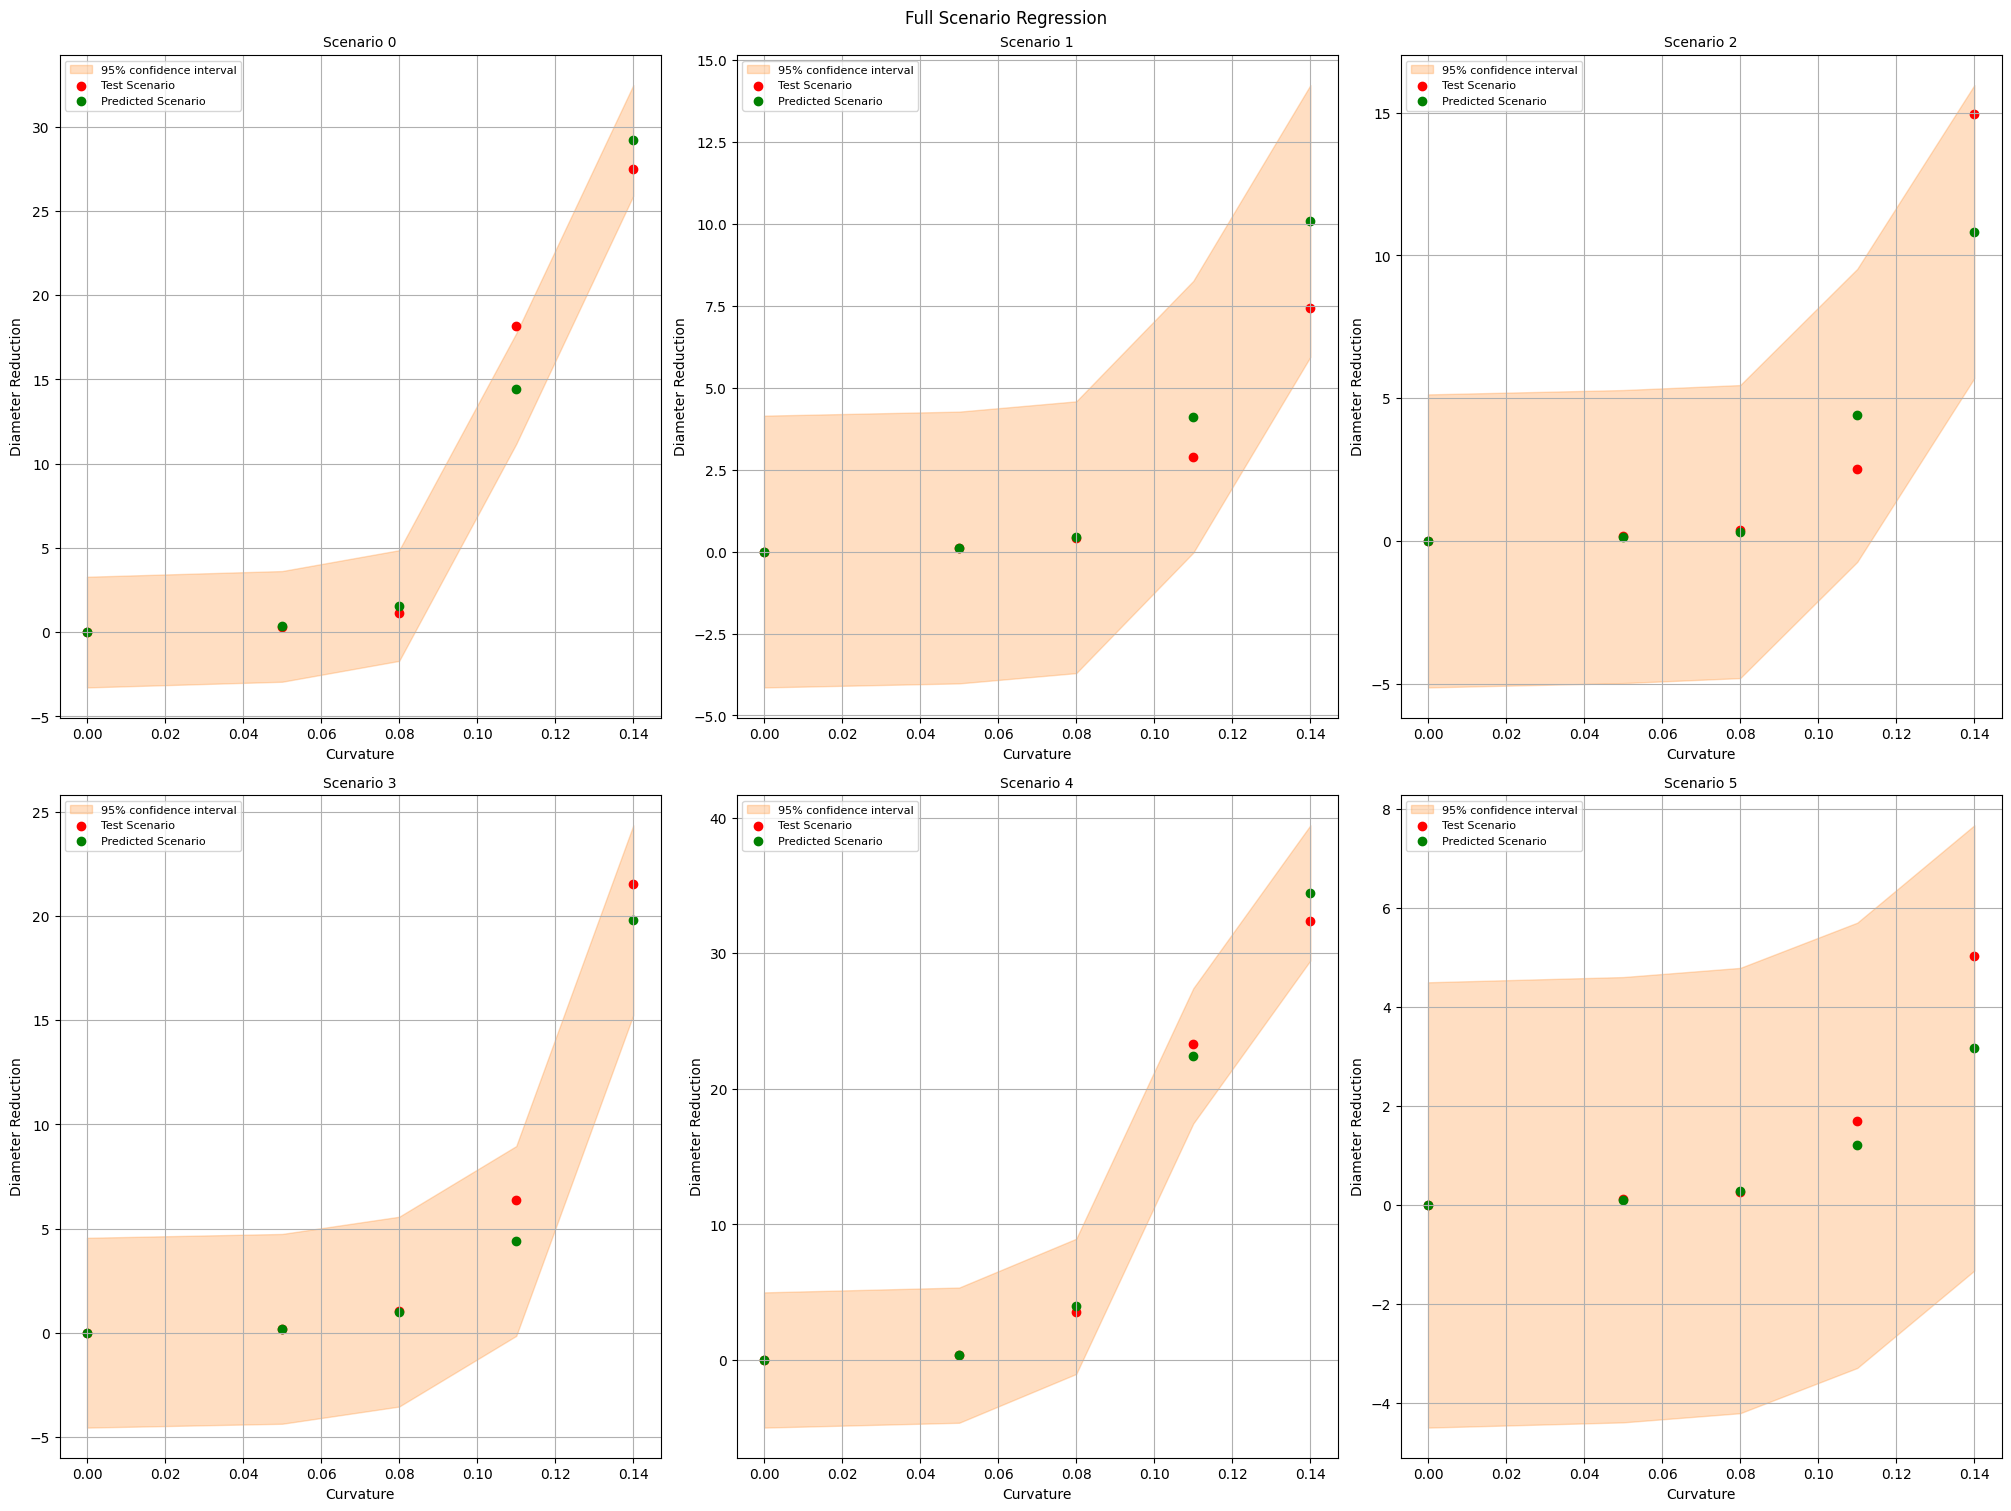

In [5]:
'''
Viene tolto une scenario, con tutte e 4 le curvature, e si cerca di predirlo
NB: togliendo uno scenario in un campionamento "intelligente", ho un lower bound delle performance,
    perchè creo un "buco" nel dominio delle simulazioni.    
'''

# Numero di colonne e righe dinamiche per il plot
num_cols = 3   # parametro puramente grafico
num_rows = (num_samples + num_cols - 1) // num_cols 

#OCIO =====================================
num_rows=2    # stampo solo le prime 2 righe
#=========================================

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 15), layout="constrained")
fig.suptitle('Full Scenario Regression')
axes = axes.flatten()  # Converti `axes` in un array monodimensionale

# Riduco i parametri ingresso (si ripetono all'interno del singolo scenario)
X_red = X_data[::n_c,:-1]  # rimuovo curvatura

# Normalizzatori per scalari e vettoriali
scaler_scalari = StandardScaler()
scaler_vettoriali = StandardScaler()

#for ivar, ax in enumerate(axes):
for ivar, ax in enumerate(axes[0:6]):  # stampo solo le prime 6 immagini 3*2
    if ivar < num_samples: 
        
        train_scalari = np.delete(X_red, ivar, axis=0)
        train_ins = np.delete(params, ivar, axis=0)  # Input di train
        train_dr = np.delete(dr, ivar, axis=0)  # Output di train
        
        test_scalari = X_red[ivar,:] 
        test_ins = params[ivar, :].flatten().reshape(1, -1)  # Input test
        test_dr = dr[ivar, :].flatten().reshape(1, -1)  # Output di test

        # Normalizzazione scalari        
        scaler_scalari.fit(train_scalari)  
        train_scalari_norm = scaler_scalari.transform(train_scalari)
        test_scalari_norm = scaler_scalari.transform(np.array([test_scalari]))

        # Normalizzazione dati vettoriali
        scaler_vettoriali.fit(train_ins)  
        train_ins_norm = scaler_vettoriali.transform(train_ins)
        test_ins_norm = scaler_vettoriali.transform(test_ins)

        # Integrazione scalari e vettoriali
        #train_ins_final = np.hstack((train_scalari_norm, train_ins_norm))
        #test_ins_final = np.hstack((test_scalari_norm, test_ins_norm))
        train_ins_final = np.hstack((train_scalari_norm, train_ins))
        test_ins_final = np.hstack((test_scalari_norm, test_ins))

        noise_std = np.std(train_dr)

        # Kernel composito, maggior flessibilità
        kernel_1 = RBF(length_scale_bounds=(1e-05, 1e6))  
        kernel_2 = Matern(length_scale_bounds=(1e-05, 1e6), nu=1.5)  
        kernel =  ConstantKernel(1.0) * (kernel_1 + kernel_2)
        
        # Definizione e addestramento del GP
        gaussian_process = GaussianProcessRegressor(kernel=kernel, optimizer="fmin_l_bfgs_b", n_restarts_optimizer=40)
        gaussian_process.fit(train_ins_final, train_dr)

        # Predizione
        mean_prediction, std_prediction = gaussian_process.predict(test_ins_final, return_std=True)

        # Plot variables
        xs_train = train_ins.flatten()   
        ys_train = train_dr             
        xs_test = test_ins.flatten()     
        ys_test = test_dr                
        ys_pred = mean_prediction       

        mean_prediction = mean_prediction.flatten()
        std_prediction = std_prediction.flatten()  

        ax.set_title(f"Scenario {ivar}", fontsize=10)
        ax.set_xlabel("Curvature")
        ax.set_ylabel("Diameter Reduction")    

        # Confidenza al 95% delle predizioni GP
        ax.fill_between(
            xs_test,
            mean_prediction - 1.96 * std_prediction,
            mean_prediction + 1.96 * std_prediction,
            color="tab:orange",
            alpha=0.25,
            label=r"95% confidence interval",
        )        
        #ax.scatter(xs_train, ys_train, s=5, color='tab:blue', alpha=0.5, label='Train Data') # Train data (grigio)        
        ax.scatter(xs_test, ys_test, color='r', label='Test Scenario') # Test data (rosso)        
        ax.scatter(xs_test, ys_pred, color='g', label='Predicted Scenario') # Predizione GP (verde)
       
        ax.legend(fontsize=8)        
        ax.grid(True)

# Rimuove subplot vuoti se il numero di scenari non è multiplo di 3
for ivar in range(num_samples, len(axes)):
    fig.delaxes(axes[ivar])

plt.show()


#### Con trasformazione logaritmica e metriche errore


--- Metriche di Errore Aggregate (Leave-One-Out) ---
Mean Squared Error (MSE):       4.3462
Root Mean Squared Error (RMSE):   2.0848
Mean Absolute Error (MAE):      1.0642
Coefficiente R²:                0.9486
-----------------------------------------------------


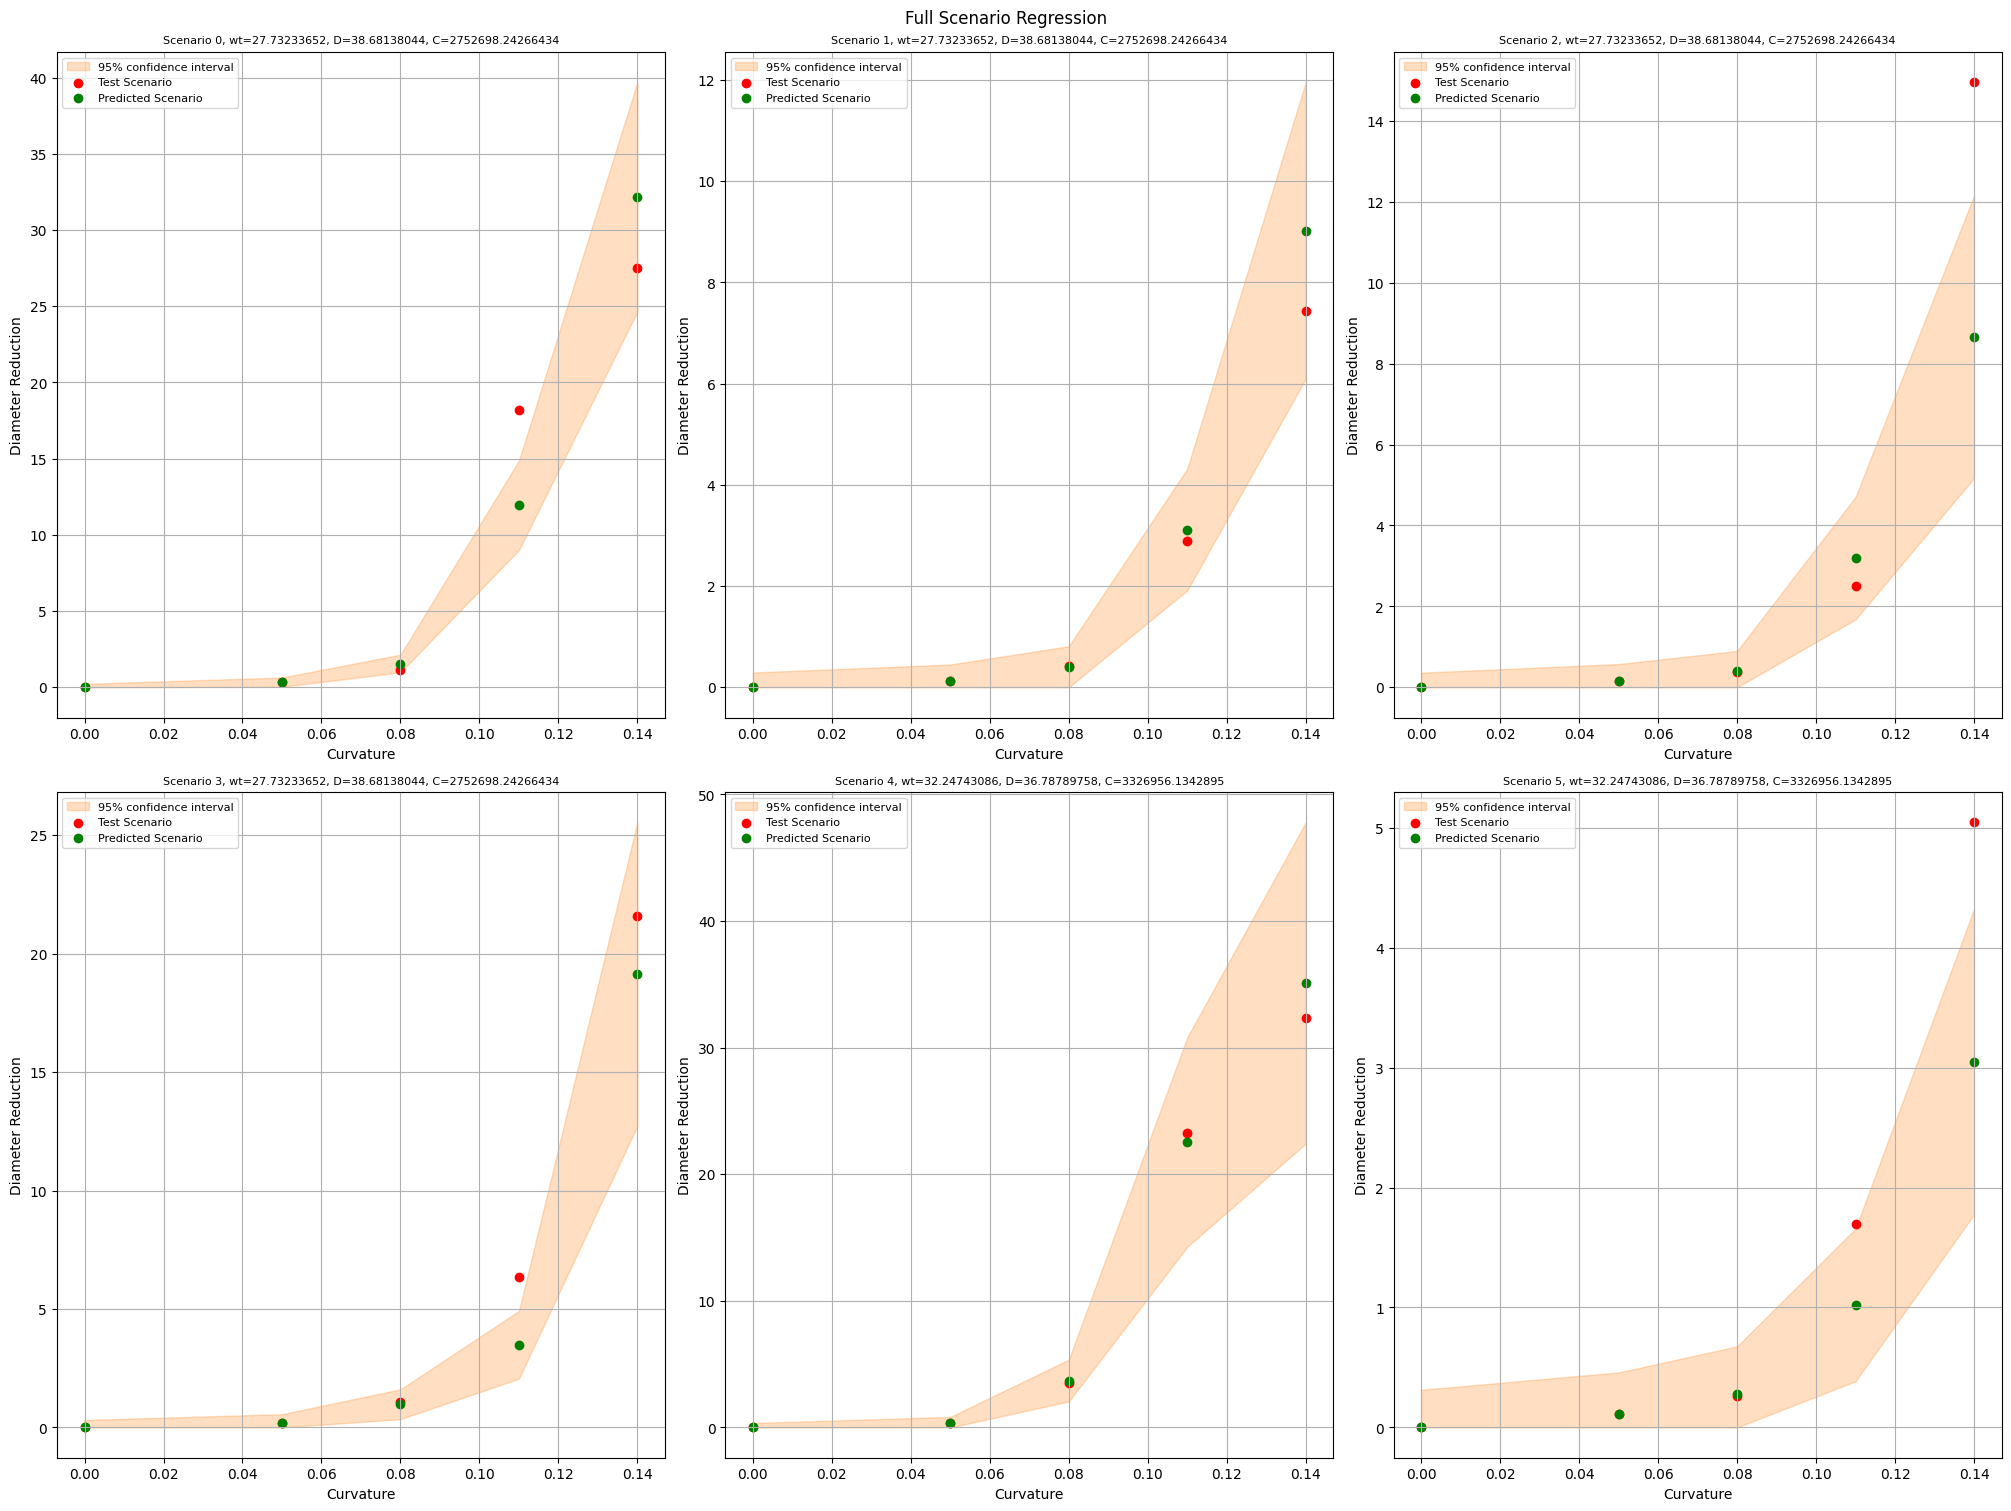

In [6]:
# Numero di colonne e righe dinamiche per il plot
num_cols = 3   

# OCIOOOOO===================
#num_rows = (num_samples + num_cols - 1) // num_cols  
num_rows = 2
#===============================

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 15), layout="constrained")
fig.suptitle('Full Scenario Regression')
axes = axes.flatten()

# Normalizzatori
scaler_scalari = StandardScaler()
scaler_vettoriali = StandardScaler()

# Inizializzazione degli accumulatori per le metriche globali
y_real_all = []
y_pred_all = []

# Definire correttamente X_red
X_red = X_data[::n_c, :-1]

#===========================================
for ivar, ax in enumerate(axes[0:num_samples]): 
#===========================================
    if ivar < num_samples:
        # Estrazione dei dati di train e test (Leave-One-Out)
        train_scalari = np.delete(X_red, ivar, axis=0)
        train_ins = np.delete(params, ivar, axis=0)
        train_dr = np.delete(dr, ivar, axis=0)
        
        test_scalari = X_red[ivar,:] 
        test_ins = params[ivar, :].flatten().reshape(1, -1)
        test_dr = dr[ivar, :].flatten().reshape(1, -1)

        # Normalizzazione
        scaler_scalari.fit(train_scalari)  
        train_scalari_norm = scaler_scalari.transform(train_scalari)
        test_scalari_norm = scaler_scalari.transform(np.array([test_scalari]))
        
        train_ins_final = np.hstack((train_scalari_norm, train_ins))
        test_ins_final = np.hstack((test_scalari_norm, test_ins))

        # Trasformazione logaritmica del target di training
        train_dr_log = np.log(train_dr + 1)  

        # Definizione e addestramento del GP
        kernel = ConstantKernel(1.0) * (RBF(length_scale_bounds=(1e-05, 1e6)) + Matern(length_scale_bounds=(1e-05, 1e6), nu=1.5))
        gaussian_process = GaussianProcessRegressor(kernel=kernel, optimizer="fmin_l_bfgs_b", n_restarts_optimizer=40)
        gaussian_process.fit(train_ins_final, train_dr_log)

        # Predizione
        mean_prediction_log, std_prediction_log = gaussian_process.predict(test_ins_final, return_std=True)

        # Inversione della trasformazione logaritmica
        mean_prediction = np.exp(mean_prediction_log) - 1
        
        # Riassegnazione delle variabili di plot
        xs_test = test_ins.flatten()      
        ys_test = test_dr.flatten()           
        ys_pred = mean_prediction.flatten()

        # Aggregazione dei risultati per le metriche finali
        y_real_all.extend(ys_test)
        y_pred_all.extend(ys_pred)
        
        # Stima della deviazione standard (opzionale, per la banda di confidenza)
        fattore_espansione = np.sqrt((np.exp(std_prediction_log**2) - 1) * np.exp(2 * mean_prediction_log + std_prediction_log**2))
        std_prediction = np.squeeze(fattore_espansione)

        ax.set_title(f"Scenario {ivar}, wt={wall_thickness[ivar]}, D={outer_diameter[ivar]}, C={axial_load[ivar]}", fontsize=8)
        ax.set_xlabel("Curvature")
        ax.set_ylabel("Diameter Reduction")    

        ax.fill_between(
            xs_test,
            np.maximum(ys_pred - 1.96 * std_prediction, 0),
            np.maximum(ys_pred + 1.96 * std_prediction, 0),
            color="tab:orange",
            alpha=0.25,
            label=r"95% confidence interval",
        )       
        ax.scatter(xs_test, ys_test, color='r', label='Test Scenario')      
        ax.scatter(xs_test, ys_pred, color='g', label='Predicted Scenario')      
        ax.legend(fontsize=8)
        ax.grid(True)

# Rimuove subplot vuoti
for i in range(num_samples, len(axes)):
    fig.delaxes(axes[i])

# Calcolo e stampa delle metriche di errore aggregate
y_real_all = np.array(y_real_all)
y_pred_all = np.array(y_pred_all)

mse = mean_squared_error(y_real_all, y_pred_all)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_real_all, y_pred_all)
r2 = r2_score(y_real_all, y_pred_all)

print("\n--- Metriche di Errore Aggregate (Leave-One-Out) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("-----------------------------------------------------")

plt.show()

### Previsione su NUOVO PUNTO

#### Training modello DR con trasformazione logaritmica

In [12]:
# Normalizzatori per scalari e vettoriali
scaler_scalari = StandardScaler()
scaler_vettoriali = StandardScaler()

# Estrazione dei dati di train
train_scalari = X_data[::n_c, :-1] #rimuovo curvatura

scaler_scalari.fit(train_scalari)
train_scalari_norm = scaler_scalari.transform(train_scalari)

scaler_vettoriali.fit(params)
train_ins_norm = scaler_vettoriali.transform(params)
train_dr_final = scaler_vettoriali.transform(dr) 

train_ins_final = train_scalari_norm

# Applica la trasformazione logaritmica (per evitare valori negativi)
train_dr_final = np.log(train_dr_final + 1)  # Trasforma il parametro di output

# Definizione del kernel
kernel = ConstantKernel(1.0) * (RBF(length_scale_bounds=(1e-05, 1e6)) + Matern(length_scale_bounds=(1e-05, 1e6), nu=1.5))

# Addestramento del GP
gaussian_process = GaussianProcessRegressor(kernel=kernel, optimizer="fmin_l_bfgs_b", n_restarts_optimizer=80)
gaussian_process.fit(train_ins_final, train_dr_final)


,kernel,"1**2 * RBF(le...ale=1, nu=1.5)"
,alpha,1e-10
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,80
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,"RBF(length_sc...ale=1, nu=1.5)"
,kernel__k1__constant_value,1.0


#### TESTING su nuovo punto DR

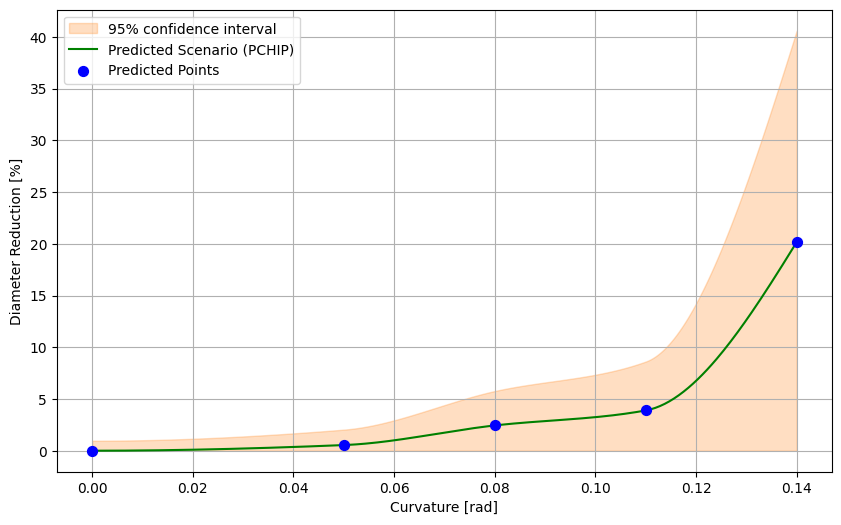

In [18]:
# SCELTA NUOVI PARAMETRI INPUT

OUTER_DIAMETER = 50 # pollici  [32 - 42]
WALL_THICKNESS = 29 # mm  [25 - 35]
AXIAL_LOAD = 1e6   # kN   [1e6 - 5e6 ]
EXT_PRESSURE = 1.5
YOUNG_MOD = 210000
STRESS_YIELD_1 = 370
STRESS_YIELD_2 = 470
EP2_MOD = 0.1
OVAL = 0.001

#---------------------------------------------------------------------------------------------

test_scalari = np.array([[OUTER_DIAMETER, WALL_THICKNESS, AXIAL_LOAD, EXT_PRESSURE, YOUNG_MOD,
                         STRESS_YIELD_1, STRESS_YIELD_2, EP2_MOD, OVAL]])  # Valori di test scelti

test_scalari_norm = scaler_scalari.transform(test_scalari)

# non sono state inserite curvature, sono valori costanti (es 0.05,..., 0.14)
test_ins_final = test_scalari_norm
test_vettoriali = params[0]

# Predizione (restituisce media e std in spazio logaritmico)
mean_prediction_log, std_prediction_log = gaussian_process.predict(test_ins_final, return_std=True)

# Inversione della trasformazione logaritmica per la media
mean_prediction = np.exp(mean_prediction_log) - 1

# Calcolo corretto della deviazione standard nello spazio originale (log-normale)
# La variabile 'std_prediction' ora contiene direttamente la deviazione standard corretta
std_prediction = np.sqrt((np.exp(std_prediction_log**2) - 1) * np.exp(2 * mean_prediction_log + std_prediction_log**2))

# Assicura che gli array siano monodimensionali per il plot
mean_prediction = mean_prediction.flatten()
std_prediction = std_prediction.flatten()
test_vettoriali = test_vettoriali.flatten() # Assicura coerenza dimensionale


# Genera un set di punti più denso per l'asse X per una curva liscia
x_smooth = np.linspace(test_vettoriali.min(), test_vettoriali.max(), 300)
# Crea un interpolatore PCHIP per la media predetta
pchip_mean = PchipInterpolator(test_vettoriali, mean_prediction)
y_smooth_mean = pchip_mean(x_smooth)
# Calcola i limiti dell'intervallo di confidenza sui punti originali
lower_bound = np.maximum(mean_prediction - 1.96 * std_prediction, 0)
upper_bound = np.maximum(mean_prediction + 1.96 * std_prediction, 0)
# Crea interpolatori PCHIP anche per i limiti dell'intervallo
pchip_lower = PchipInterpolator(test_vettoriali, lower_bound)
pchip_upper = PchipInterpolator(test_vettoriali, upper_bound)
# Valuta i limiti sui punti densi
y_smooth_lower = pchip_lower(x_smooth)
y_smooth_upper = pchip_upper(x_smooth)

# Plot della predizione con curva PCHIP e intervallo di confidenza interpolato
plt.figure(figsize=(10, 6))
plt.xlabel("Curvature [rad]")
plt.ylabel("Diameter Reduction [%]")

# Utilizza i dati interpolati per il plot
plt.fill_between(x_smooth, y_smooth_lower, y_smooth_upper,
                 color="tab:orange",
                 alpha=0.25,
                 label=r"95% confidence interval")

plt.plot(x_smooth, y_smooth_mean, color="g", label="Predicted Scenario (PCHIP)")
plt.scatter(test_vettoriali, mean_prediction, color="blue", s=50, zorder=5, label="Predicted Points")

plt.legend()
plt.grid(True)
plt.show()

## <span style="color:magenta"> Multiscenario Prediction (Area Profile) </span>

#### Preliminari

In [9]:
# Riduco i parametri ingresso (si ripetono all'interno del singolo scenario)
X_red = X_data[::n_c,:-1]  # rimuovo curvatura

# Trasformo in un numpy array
a_profiles = np.array(def_A) 

# Rimuovo gli zeri usati prima, la zero è undeformed, non interessante
params_ap = params[:, 1:] 

# Numero tutti gli scenari
num_samples = a_profiles.shape[0] // n_c  

# Numero ascisse curvilinee
num_abs = pipe_abs.shape[0]   

ap_tot = np.zeros((num_samples, n_c, num_abs)) 
ap_buf = np.zeros(a_profiles.shape[0]) # buffer

# Creo nuova matrice per agevolare predizioni
for jj in range(num_abs):
    ap_buf = a_profiles[:, jj] # pesca la ascissa jj-esima 
    for ii in range(num_samples): 
        ap_tot[ii, :, jj] = ap_buf[ii * n_c:(ii+1) * n_c] # per scaglioni di n_c crea la nuova matrice  


### Logica "cut" 

#### Predico singole abs

abs:  0  --------


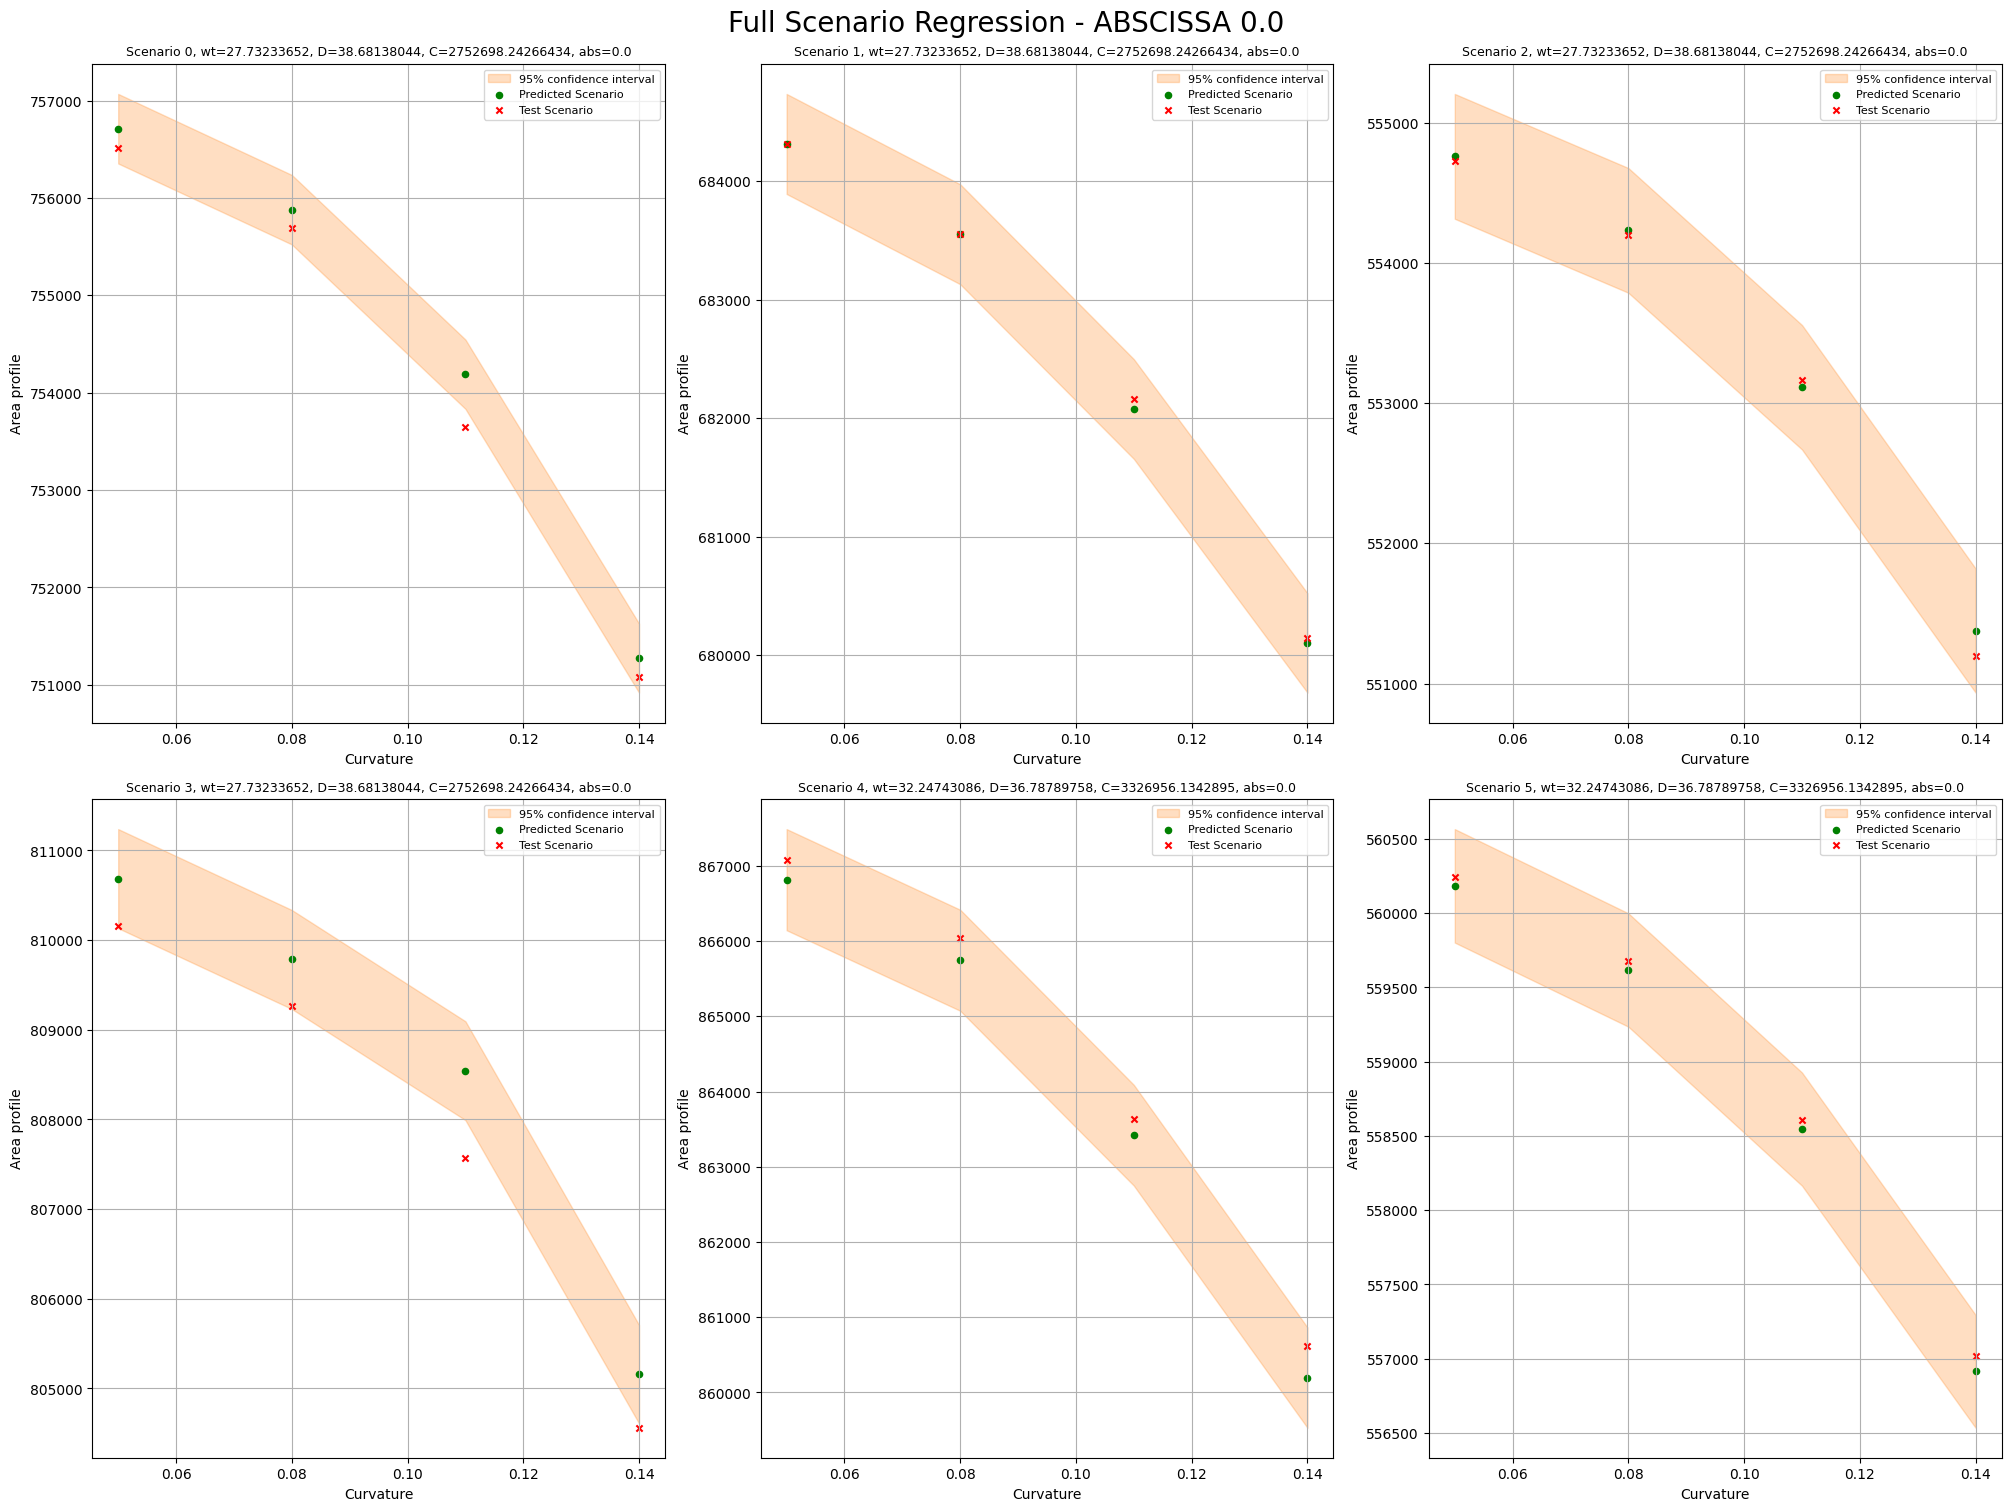

abs:  1  --------


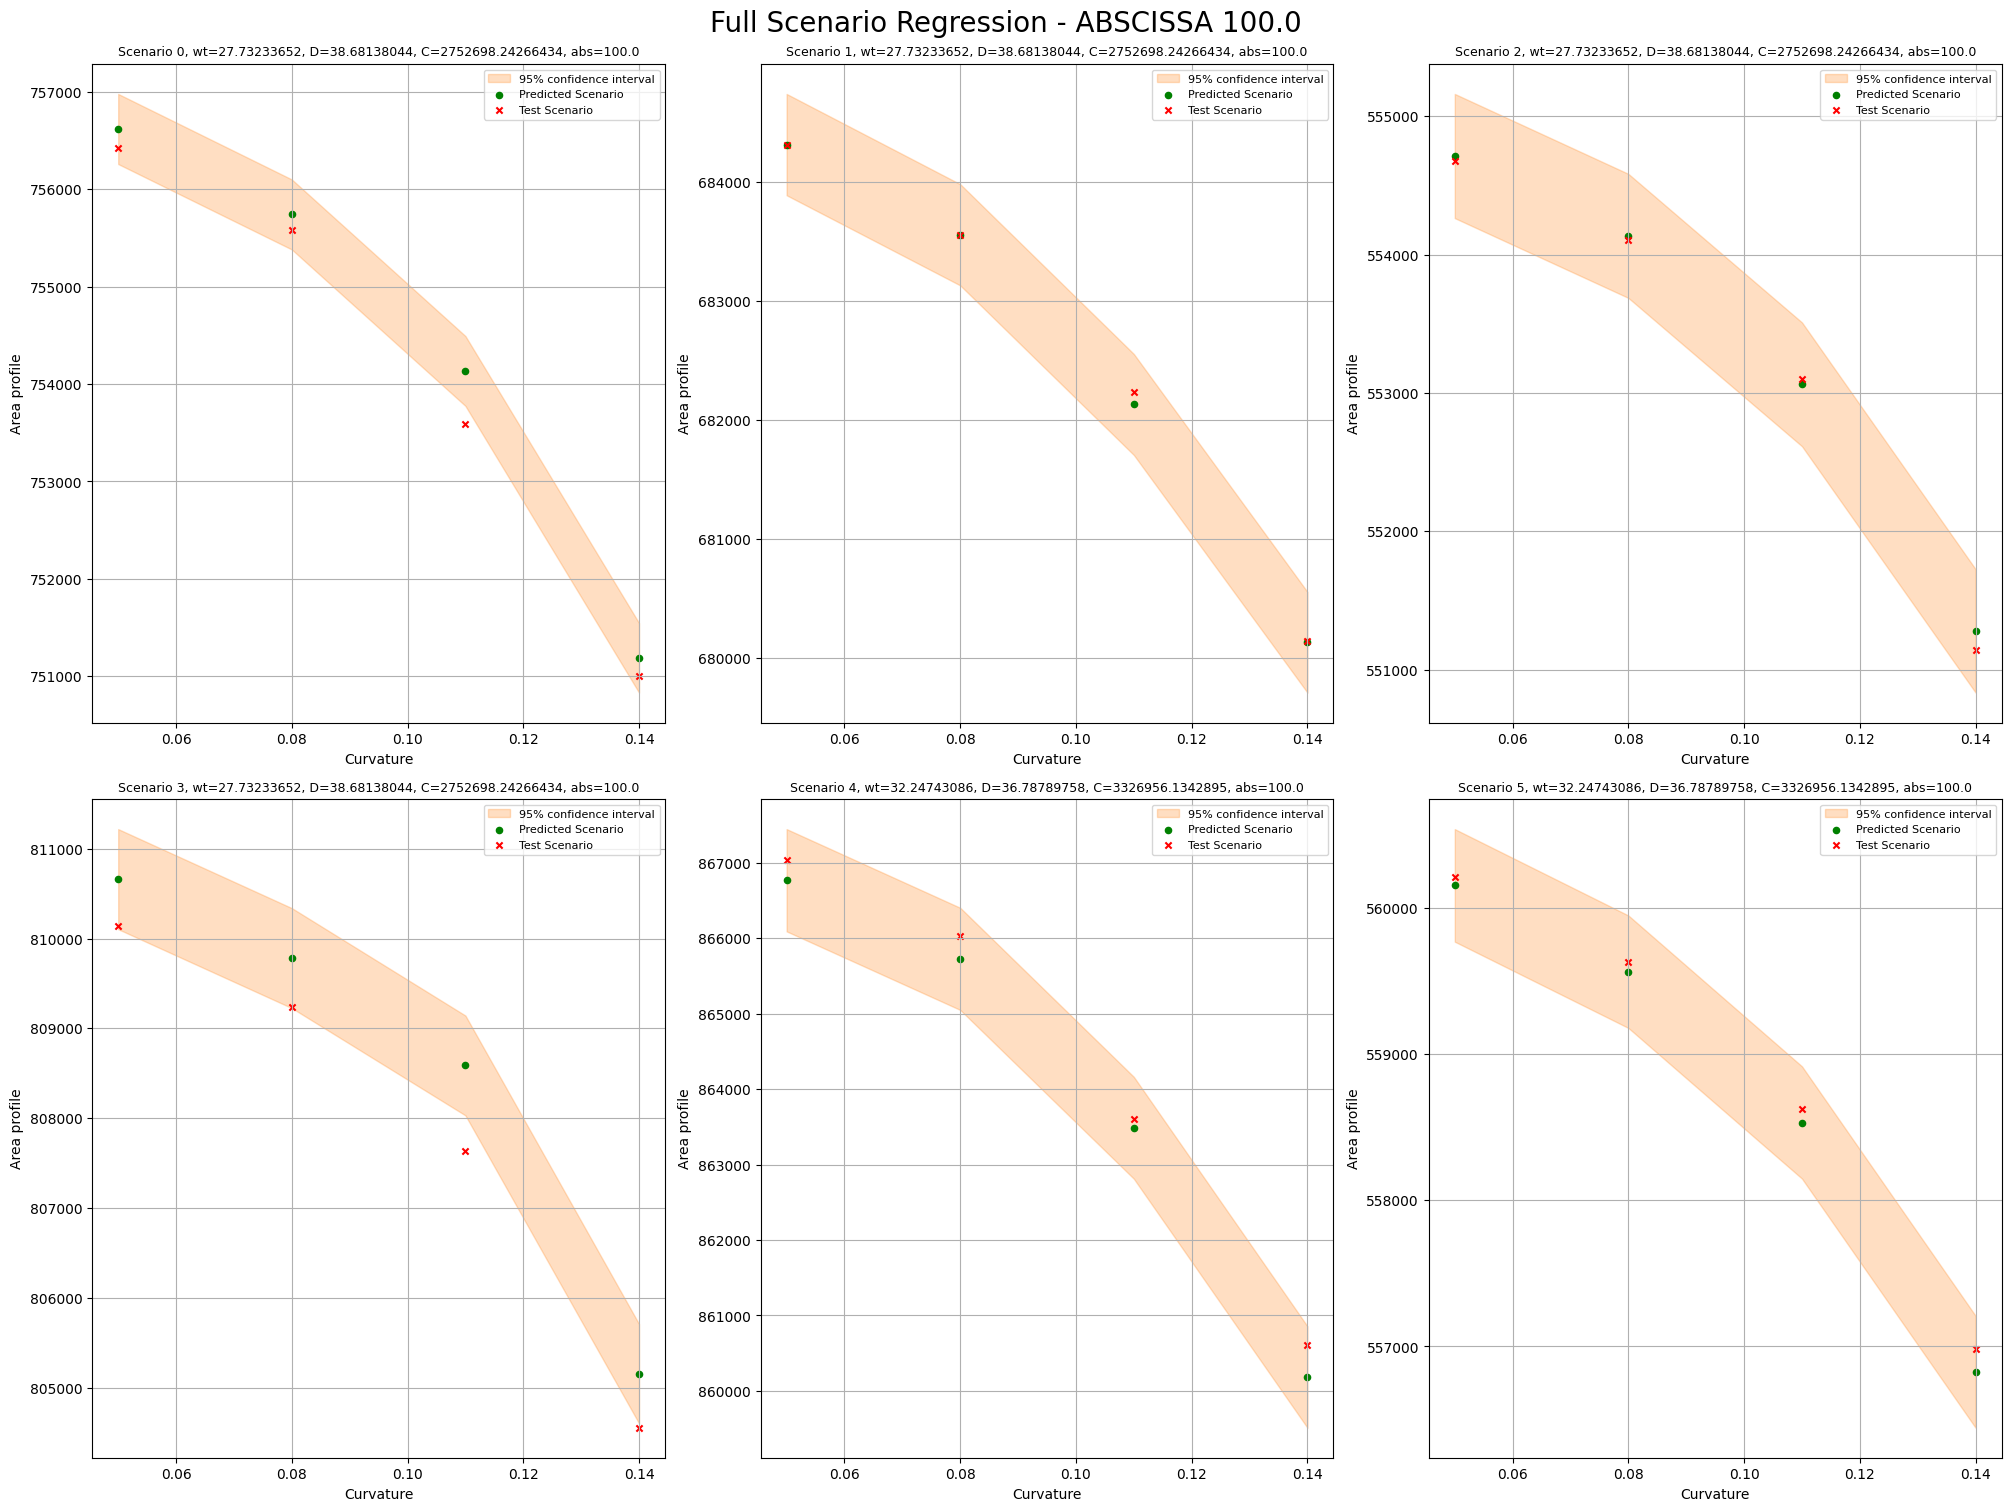

abs:  2  --------


KeyboardInterrupt: 

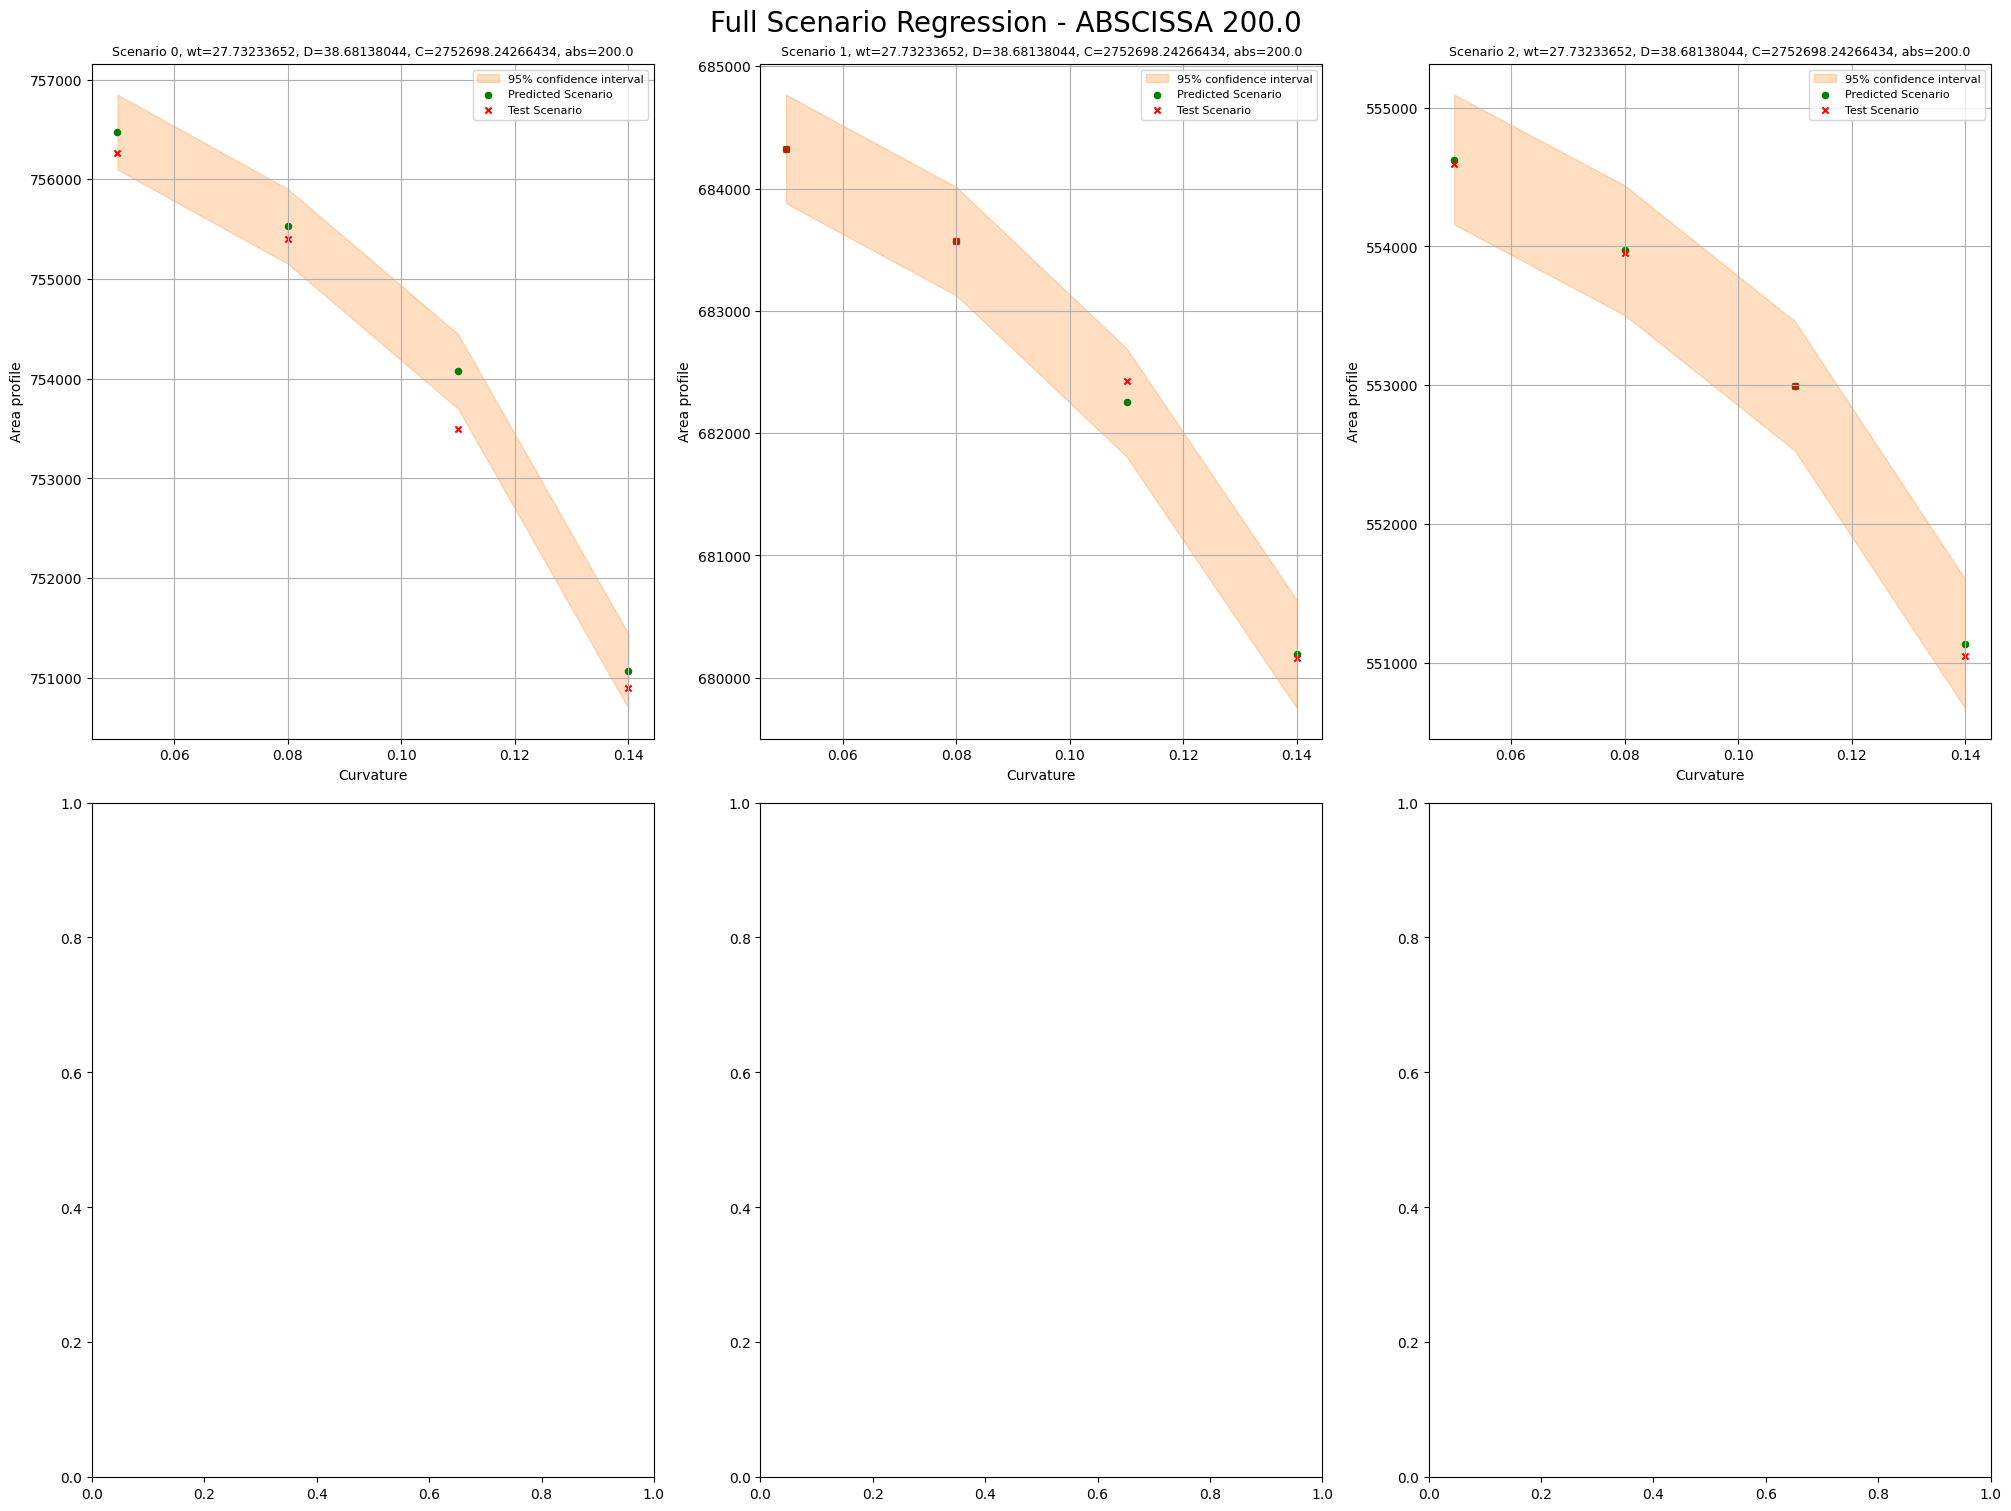

In [10]:
# Sopprime i warning di Scikit-learn relativi alla convergenza
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

mean_pred = np.full((num_samples, n_c, num_abs), np.nan)
std_pred = np.full((num_samples, n_c, num_abs), np.nan) 

# Normalizzatori per scalari e vettoriali
scaler_scalari = StandardScaler()
scaler_vettoriali = StandardScaler()

for jj in range(num_abs):    
    fig, axes = plt.subplots(2, 3, figsize=(20, 15), layout="constrained")
    fig.suptitle(f'Full Scenario Regression - ABSCISSA {pipe_abs[jj]}', fontsize=20)
    axes = axes.flatten()
    print("abs: ", jj, " --------")
    
    for ivar, ax in enumerate(axes):
        if ivar < num_samples:
            # Estrazione dei dati di train e test
            train_scalari = np.delete(X_red, ivar, axis=0) 
            train_ins = np.delete(params_ap, ivar, axis=0)  
            train_ap = np.delete(ap_tot[:, :, jj], ivar, axis=0)

            test_scalari = X_red[ivar,:]
            test_ins = params_ap[ivar, :].flatten().reshape(1, -1)  
            test_ap = ap_tot[ivar, :, jj].flatten().reshape(1, -1)  
            
            # Normalizzazioni e trasformazioni           
            train_ap_log = np.log(train_ap + 1) # log transform
            
            scaler_scalari.fit(train_scalari)  
            train_scalari_norm = scaler_scalari.transform(train_scalari)
            test_scalari_norm = scaler_scalari.transform(np.array([test_scalari]))
            
            # Nota: la normalizzazione dei vettori qui non è usata per l'input del GP
            # scaler_vettoriali.fit(train_ins)  
            # train_ins_norm = scaler_vettoriali.transform(train_ins)
            # test_ins_norm = scaler_vettoriali.transform(test_ins)

            train_ins_final = np.hstack((train_scalari_norm, train_ins))
            test_ins_final = np.hstack((test_scalari_norm, test_ins))

            # Definizione e addestramento GP                             
            kernel = ConstantKernel(1.0) * (
                RBF( length_scale_bounds=(1e-5, 1e7)) + 
                Matern(length_scale=10, length_scale_bounds=(1e-5, 1e7), nu=1.5))
            
            gaussian_process = GaussianProcessRegressor(
                kernel=kernel, optimizer="fmin_l_bfgs_b", n_restarts_optimizer=20)

            gaussian_process.fit(train_ins_final, train_ap_log)

            # Predizione (restituisce media e std in SPAZIO LOGARITMICO)
            mean_prediction_log, std_prediction_log = gaussian_process.predict(test_ins_final, return_std=True)
            
            # --- Inversione della Trasformazione ---

            # 1. Calcola la media nello spazio originale
            mean_prediction = np.exp(mean_prediction_log) - 1
            
            # 2. Calcola la deviazione standard nello spazio originale (per salvataggio dati)
            # Questa è la formula corretta per la varianza di una distribuzione log-normale
            variance_original = (np.exp(std_prediction_log**2) - 1) * np.exp(2 * mean_prediction_log + std_prediction_log**2)
            std_prediction_original = np.sqrt(variance_original)

            # 3. Calcola i limiti del CI al 95% nello spazio logaritmico (dove è simmetrico)
            lower_bound_log = mean_prediction_log - 1.96 * std_prediction_log
            upper_bound_log = mean_prediction_log + 1.96 * std_prediction_log
            
            # 4. Trasforma i LIMITI nello spazio originale
            # Questo produce l'intervallo di confidenza asimmetrico corretto
            lower_bound_final = np.exp(lower_bound_log) - 1
            upper_bound_final = np.exp(upper_bound_log) - 1
            
            xs_test = test_ins.flatten()
            ys_test = test_ap.flatten()
            ys_pred = mean_prediction.flatten() # Usa la media già trasformata

            # Salva i risultati per questo scenario
            mean_pred[ivar,:,jj] = mean_prediction.squeeze()
            std_pred[ivar,:,jj] = std_prediction_original.squeeze()
            
            ax.set_title(
                f"Scenario {ivar}, wt={wall_thickness[ivar]}, D={outer_diameter[ivar]}, C={axial_load[ivar]}, abs={pipe_abs[jj]}", fontsize=9
            )
            ax.set_xlabel("Curvature")
            ax.set_ylabel("Area profile")

            # Usa i limiti calcolati direttamente, non mean +/- std
            ax.fill_between(
                xs_test,
                np.maximum(lower_bound_final.flatten(), 0), # Limite inferiore, con clipping a 0
                upper_bound_final.flatten(),               # Limite superiore
                color="tab:orange", alpha=0.25, label=r"95% confidence interval"
            )
            
            ax.scatter(xs_test, ys_pred, color='g', s=20, label='Predicted Scenario') # s=20 per migliore visibilità
            ax.scatter(xs_test, ys_test, color='r', s=20, marker='x', label='Test Scenario') # marker='x' per distinguere
            ax.legend(fontsize=8)
            ax.grid(True)
            
    # Rimuove i subplot vuoti
    for i in range(num_samples, len(axes)):
        fig.delaxes(axes[i])

    # Mostra la figura completata per l'ascissa jj
    plt.show()

#### Error metrics plot

In [ ]:
# Impostazioni della Griglia Fissa
num_rows = 6
num_cols = 4
total_plots_to_show = num_rows * num_cols

# Creazione della Figura e della Griglia
fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 18), layout="constrained", squeeze=False)
axes = axes.flatten()

# Inizializzazione degli accumulatori per le metriche
y_real_flat = []
y_pred_flat = []

# Ciclo di Plotting
for plot_idx in range(total_plots_to_show):
    ax = axes[plot_idx]
    
    ii = plot_idx // n_c
    nn = plot_idx % n_c

    if ii >= num_samples:
        ax.axis('off')
        continue

    # Estrazione dei dati
    pred = mean_pred[ii, nn, :]
    true = ap_tot[ii, nn, :].flatten()
    # Estrarre la deviazione standard corrispondente ---
    std = std_pred[ii, nn, :]
    abs_len = pred.shape[0]
    
    # Aggregazione dei risultati per le metriche finali
    y_real_flat.extend(true)
    y_pred_flat.extend(pred)

    # Includere l'intervallo di confidenza nel calcolo dei limiti Y ---
    lower_bound = np.maximum(pred - 1.96 * std, 0)
    upper_bound = pred + 1.96 * std
    combined_data = np.concatenate((pred, true, lower_bound, upper_bound))

    # Logica per la scala Y adattiva (leggermente modificata per includere la banda di confidenza)
    data_min = np.min(combined_data)
    data_max = np.max(combined_data)
    margin = abs((data_max - data_min) * 0.05) # Margine del 5% del range
    ax.set_ylim(data_min - margin, data_max + margin)
    
    # Esegue il plot sull'asse specifico
    # Aggiungere il plot dell'intervallo di confidenza ---
    ax.fill_between(pipe_abs[-abs_len:], 
                      lower_bound, 
                      upper_bound,
                      color="tab:orange", alpha=0.25, label=r"95% confidence interval")
    
    ax.plot(pipe_abs[-abs_len:], pred, 'r-', label='Predicted')
    ax.plot(pipe_abs[-abs_len:], true[-abs_len:], 'g--', label='True')
    ax.set_title(f'Scenario {ii}, Curva {nn}')
    ax.grid(True)

# Pulizia della Figura
fig.supxlabel('Curvilinear Abscissa')
fig.supylabel('Area Profile')
handles, labels = ax.get_legend_handles_labels()
# Raggruppa le label per evitare duplicati nella legenda principale
unique_labels = dict(zip(labels, handles))
fig.legend(unique_labels.values(), unique_labels.keys(), loc='upper right')

# Calcolo e stampa delle metriche di errore aggregate (INVARIATO)
y_real_flat = np.array(y_real_flat)
y_pred_flat = np.array(y_pred_flat)

mse = mean_squared_error(y_real_flat, y_pred_flat)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_real_flat, y_pred_flat)
r2 = r2_score(y_real_flat, y_pred_flat)

print(f"\n--- Metriche di Errore (calcolate sui {total_plots_to_show} profili visualizzati) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("--------------------------------------------------------------------")

# Mostra la figura completa
plt.show()

### Logica "black-box"

#### Prediction - Error metrics plot

In [ ]:
# FASE 1: Preparazione Strutturale dei Dati 

# Calcola il numero di scenari e di curve per scenario
n_c = 4
num_samples = a_profiles.shape[0] // n_c
n_abs = num_abs

# Estrae la matrice X_data grezza
X_data_grezzo = X_data[:, :-1]
X_scalars_unici = X_data_grezzo[::n_c, :]
assert X_scalars_unici.shape[0] == num_samples, \
    f"ERRORE: La de-duplicazione non è riuscita. Righe uniche: {X_scalars_unici.shape[0]}, Scenari attesi: {num_samples}"

# Preparazione finale dei dati
ap_tot_r = ap_tot.reshape(num_samples * n_c, n_abs)
params_ap_r = params_ap.flatten().reshape(-1, 1)
X_scalars_repeated = np.repeat(X_scalars_unici, repeats=n_c, axis=0)
X_final = np.hstack((X_scalars_repeated, params_ap_r))

print(f"\nMatrice di input X_final creata con shape: {X_final.shape}")
print(f"Matrice di output ap_tot_r creata con shape: {ap_tot_r.shape}")

#--------------------------------------------------------------------------------------

# FASE 2: Calcolo e Salvataggio delle Predizioni ---

# Inizializza gli array per salvare le predizioni e i limiti dell'intervallo
# NOTA: Ora salviamo esplicitamente i limiti inferiore e superiore
num_predictions_to_run = 6 * n_c
mean_pred_storage = np.zeros((num_predictions_to_run, n_abs))
lower_bound_storage = np.zeros((num_predictions_to_run, n_abs))
upper_bound_storage = np.zeros((num_predictions_to_run, n_abs))

scaler = StandardScaler()

# Ciclo di validazione Leave-One-Out
for ii in range(num_predictions_to_run):
    print(f"Calcolo per la curva #{ii+1}/{num_predictions_to_run}...")

    # Divisione Train/Test
    train_X = np.delete(X_final, ii, axis=0)
    train_Y_log = np.log(np.delete(ap_tot_r, ii, axis=0) + 1)
    test_X = X_final[ii, :].reshape(1, -1)

    # Normalizzazione
    train_X_norm = scaler.fit_transform(train_X)
    test_X_norm = scaler.transform(test_X)
    
    # Definizione e addestramento GP
    kernel = ConstantKernel(1.0) * (
        RBF(length_scale_bounds=(1e-5, 1e7)) +
        Matern(length_scale=10, length_scale_bounds=(1e-5, 1e7), nu=1.5)
    )
    gaussian_process = GaussianProcessRegressor(
        kernel=kernel, optimizer="fmin_l_bfgs_b", n_restarts_optimizer=20
    )
    gaussian_process.fit(train_X_norm, train_Y_log)
    
    # Predizione nello spazio logaritmico
    mean_prediction_log, std_prediction_log = gaussian_process.predict(test_X_norm, return_std=True)
    
    # --- MODIFICA CRITICA: Calcolo corretto dell'intervallo ---
    # 1. Calcola i limiti nello spazio logaritmico (Gaussiano e simmetrico)
    lower_bound_log = mean_prediction_log - 1.96 * std_prediction_log
    upper_bound_log = mean_prediction_log + 1.96 * std_prediction_log

    # 2. Applica la trasformazione inversa a media e limiti separatamente
    mean_prediction = np.exp(mean_prediction_log) - 1
    lower_bound = np.exp(lower_bound_log) - 1
    upper_bound = np.exp(upper_bound_log) - 1

    # Salva i risultati
    mean_pred_storage[ii, :] = mean_prediction.flatten()
    lower_bound_storage[ii, :] = lower_bound.flatten()
    upper_bound_storage[ii, :] = upper_bound.flatten()

print("Calcolo di tutte le predizioni completato.")

# --------------------------------------------------------------------------------------
# FASE 3: Plotting e Calcolo Metriche

# Impostazioni Griglia
num_rows = 6
num_cols = 4
total_plots_to_show = num_rows * num_cols

# Creazione Figura
fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 18), layout="constrained", squeeze=False)

# Inizializzazione accumulatori
y_real_all = []
y_pred_all = []

for ii in range(6): 
    for nn in range(n_c): 
        
        ax = axes[ii, nn]
        
        plot_idx = ii * n_c + nn
        
        # Estrai predizione, valore reale e limiti dell'intervallo
        pred = mean_pred_storage[plot_idx, :]
        true = ap_tot_r[plot_idx, :]
        lower_bound_corr = lower_bound_storage[plot_idx, :]
        upper_bound_corr = upper_bound_storage[plot_idx, :]
        
        # Applica vincolo fisico di non-negatività
        lower_bound_corr = np.maximum(lower_bound_corr, 0)
        
        # Aggregazione per metriche
        y_real_all.extend(true)
        y_pred_all.extend(pred)
        
        # Adattare la scala Y per includere la banda di predizione
        combined_data = np.concatenate((pred, true, lower_bound_corr, upper_bound_corr))
        data_min = np.min(combined_data)
        data_max = np.max(combined_data)
        margin = abs((data_max - data_min) * 0.05)
        ax.set_ylim(data_min - margin, data_max + margin)

        # --- MODIFICA CRITICA: Plot dell'intervallo di predizione asimmetrico corretto ---
        ax.fill_between(pipe_abs, lower_bound_corr, upper_bound_corr, 
                        color='tab:orange', alpha=0.25, label='Intervallo Pred. 95%')

        # Plot dei dati
        ax.plot(pipe_abs, pred, 'r-', label='Predetto')
        ax.plot(pipe_abs, true, 'g--', label='Reale')
        ax.set_title(f'Scenario {ii}, Curva {nn}', fontsize=9)
        ax.grid(True)

# Aggiungi etichette e legenda
fig.supxlabel('Ascissa Curvilinea')
fig.supylabel('Profilo Area')
handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles)) # Evita etichette duplicate
fig.legend(unique_labels.values(), unique_labels.keys(), loc='upper right')

# Calcolo e stampa delle metriche di errore (INVARIATO)
y_real_all = np.array(y_real_all)
y_pred_all = np.array(y_pred_all)
mse = mean_squared_error(y_real_all, y_pred_all)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_real_all, y_pred_all)
r2 = r2_score(y_real_all, y_pred_all)

print(f"\n--- Metriche di Errore (calcolate sui {total_plots_to_show} profili visualizzati) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("--------------------------------------------------------------------")

plt.show()